<a href="https://colab.research.google.com/github/AnshG-19/Blackhole_simulator_rayTracing/blob/main/notebooks/01_black_hole_geometry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install numpy scipy matplotlib plotly


# Black Hole Simulator — Geometry

## Objective
Explore the geometry of a non-rotating Schwarzschild black hole.

## Topics
- Schwarzschild radius
- Event horizon
- Photon sphere
- Visualizing the black hole and surrounding space

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
print("NumPy version:", np.__version__)
print("Black hole geometry notebook initialized.")

NumPy version: 2.1.3
Black hole geometry notebook initialized.


In [5]:
#physical constants
G = 6.67430e-11       # Gravitational constant, m^3 kg^-1 s^-2
c = 299792458         # Speed of light, m/s
M_sun = 1.98847e30    # Mass of the Sun, kg
#mass of black hole
mass= 10*M_sun
print("blackhole mass: ",mass, "kg")

blackhole mass:  1.98847e+31 kg


# Schwarzschild radius

In [14]:
r_s = (2*G*mass)/(c**2)
print("Schwarzchild radius: ",r_s,"meters")

Schwarzchild radius:  29533.393820668785 meters


# Photon sphere radius

In [18]:
r_ph = (3*G*mass)/(c**2)
print("Photon sphere radius: ",r_ph,"meters")

Photon sphere radius:  44300.090731003176 meters


Create a simple black hole diagram


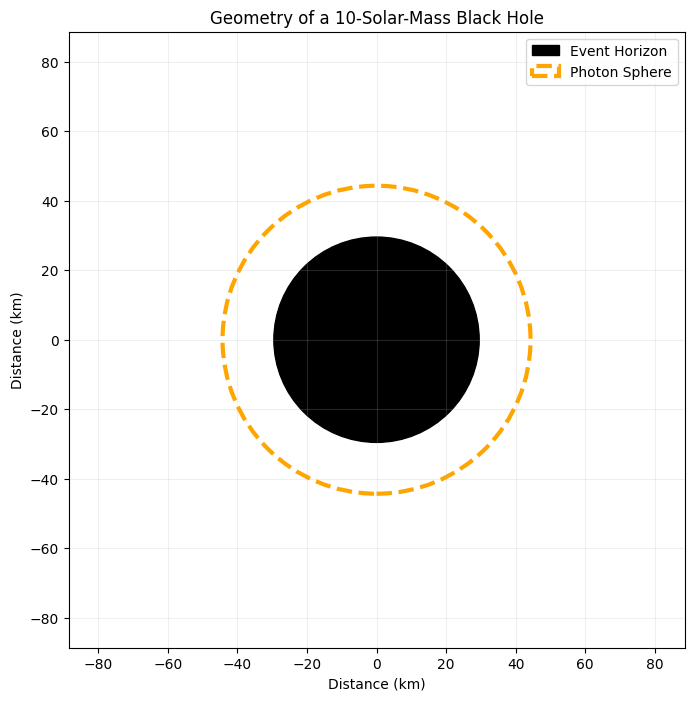

In [32]:
fig, ax = plt.subplots(figsize=(8, 8))

# Event horizon
event_horizon = Circle(
    (0, 0),
    r_s / 1000,
    color="black",
    label="Event Horizon"
)

# Photon sphere
photon_sphere = Circle(
    (0, 0),
    r_ph / 1000,
    fill=False,
    linestyle="--",
    linewidth=3,
    edgecolor="orange",
    label="Photon Sphere"
)

# Add both circles to the plot
ax.add_patch(event_horizon)
ax.add_patch(photon_sphere)

# Set the viewing area
limit = 2 * r_ph / 1000
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_aspect("equal")

# Labels and styling
ax.set_xlabel("Distance (km)")
ax.set_ylabel("Distance (km)")
ax.set_title("Geometry of a 10-Solar-Mass Black Hole")
ax.legend()
ax.grid(alpha=0.2)

plt.show()

#Add a starfield around the black hole


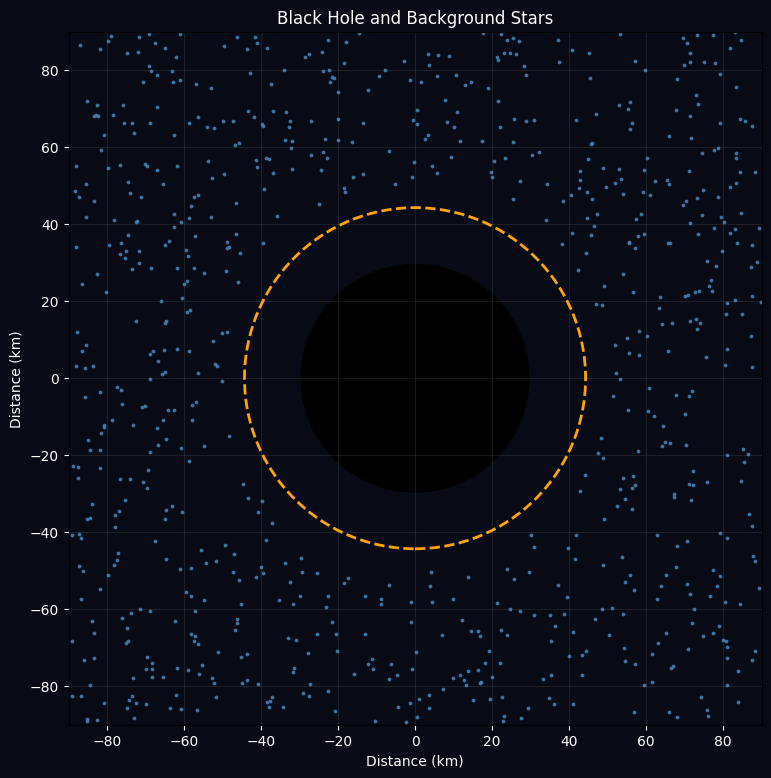

In [37]:
# Generate reproducible random star positions
np.random.seed(42)

number_of_stars = 1000
x_stars = np.random.uniform(-90, 90, number_of_stars)
y_stars = np.random.uniform(-90, 90, number_of_stars)

# Exclude stars from the central region to keep the diagram readable
distances = np.sqrt(x_stars**2 + y_stars**2)
mask = distances > 50

x_stars = x_stars[mask]
y_stars = y_stars[mask]

fig, ax = plt.subplots(figsize=(9, 9))

# Background stars
ax.scatter(
    x_stars,
    y_stars,
    s=3,
    color="steelblue",
    alpha=0.8,
    label="Background Stars"
)

# Event horizon and photon sphere
ax.add_patch(Circle((0, 0), r_s / 1000, color="black"))
ax.add_patch(
    Circle(
        (0, 0),
        r_ph / 1000,
        fill=False,
        linestyle="--",
        linewidth=2,
        color="orange"
    )
)

ax.set_xlim(-90, 90)
ax.set_ylim(-90, 90)
ax.set_aspect("equal")
ax.set_facecolor("#080b16")
fig.patch.set_facecolor("#080b16")

ax.set_xlabel("Distance (km)", color="white")
ax.set_ylabel("Distance (km)", color="white")
ax.set_title("Black Hole and Background Stars", color="white")
ax.tick_params(colors="white")
ax.grid(alpha=0.12)

plt.show()

#Verify your results

In [27]:
print("Black Hole Simulator — Geometry Check")
print("-------------------------------------")
print(f"Mass: {mass / M_sun:.1f} solar masses")
print(f"Event horizon radius: {r_s / 1000:.2f} km")
print(f"Photon sphere radius: {r_ph / 1000:.2f} km")
print(f"Photon sphere / event horizon ratio: {r_ph / r_s:.2f}")

Black Hole Simulator — Geometry Check
-------------------------------------
Mass: 10.0 solar masses
Event horizon radius: 29.53 km
Photon sphere radius: 44.30 km
Photon sphere / event horizon ratio: 1.50
